# Spread Locator: A Statistical Distribution Analysis Model
## Part B - Data Analysis & Testing Tasks

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
import os

os.makedirs("charts", exist_ok=True)
sns.set(style="whitegrid")

df = pd.read_excel("spread_locator_dataset.xlsx")
print("Shape:", df.shape)
print(df.head())
print("\nMissing values:\n", df.isnull().sum())
print(df.describe())

amount = df["transaction_amount"]
print("\nSkewness of amount =", round(amount.skew(), 3))

Shape: (220, 7)
                         transaction_id customer_id  transaction_amount  \
0  e98aa092-3770-4fdb-9502-5b5a6a244811    CUST2824             3821.34   
1  11ba6918-dba0-41e5-96cf-f5a7b95f0103    CUST1409             2781.84   
2  82b7654b-6eb7-4579-89a0-1a9edec0a7bb    CUST5506             4120.97   
3  f7166574-f400-4d53-b526-0b11f6619ddf    CUST5012             6383.78   
4  8632fe26-b507-4068-9c68-1b2fa04fecb3    CUST4657             2651.61   

  transaction_date  transaction_count region transaction_status  
0       2023-01-26                  3  North               Fail  
1       2023-01-28                  0   East               Fail  
2       2023-01-28                  0  South               Fail  
3       2023-01-18                  2  South            Success  
4       2023-01-04                  4  North            Success  

Missing values:
 transaction_id        0
customer_id           0
transaction_amount    0
transaction_date      0
transaction_count     0

**Interpretation:** The dataset has 220 transactions (1 Jan - 31 Jan 2023) with no missing values. The average transaction amount is about Rs 3,365, but the maximum is Rs 20,463. The skewness is about 3.76, so the amounts are strongly right-skewed (a few very large purchases).

## Task 1: Fit the data to Bernoulli and Binomial distributions (transaction occurrence & weekly count).

Probability of success (p) = 0.4455
Probability of fail (1-p)  = 0.5545
Mean = 0.4455  Variance = 0.247


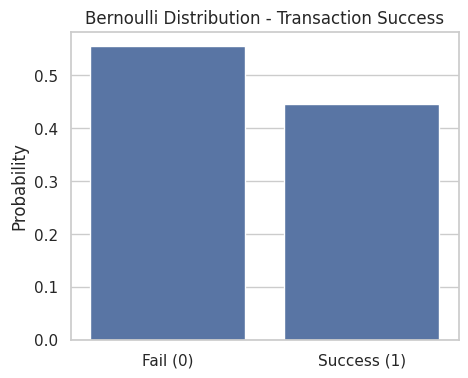

In [2]:
# Bernoulli: each transaction is Success (1) or Fail (0)
df["success"] = (df["transaction_status"] == "Success").astype(int)
p = df["success"].mean()

print("Probability of success (p) =", round(p, 4))
print("Probability of fail (1-p)  =", round(1 - p, 4))
print("Mean =", round(p, 4), " Variance =", round(p * (1 - p), 4))

plt.figure(figsize=(5, 4))
sns.barplot(x=["Fail (0)", "Success (1)"], y=[1 - p, p])
plt.title("Bernoulli Distribution - Transaction Success")
plt.ylabel("Probability")
plt.savefig("charts/1a_bernoulli.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation:** The probability of a successful transaction is about 0.4455 and of a failed one is 0.5545. So more than half of all transactions fail, which is a big concern for the e-commerce platform (payment or technical issues should be checked).

n = 9  p = 0.3172


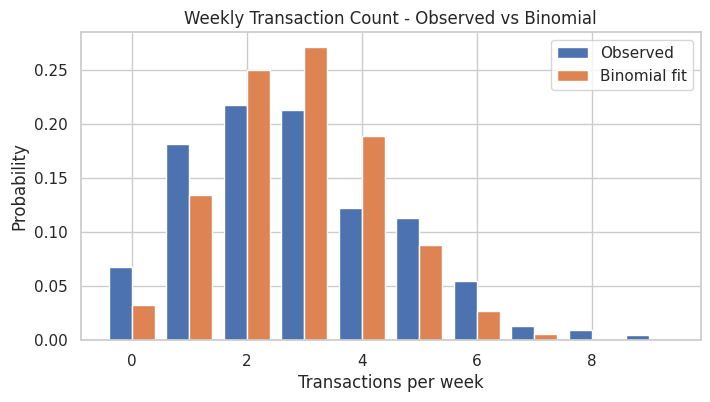

Binomial mean = 2.855  variance = 1.949
Actual mean = 2.855  actual variance = 3.23


In [3]:
# Binomial: transaction_count = number of transactions by a customer in a week
# n = maximum weekly count, p = mean / n
n = df["transaction_count"].max()
p_bin = df["transaction_count"].mean() / n
print("n =", n, " p =", round(p_bin, 4))

k = np.arange(0, n + 1)
observed = df["transaction_count"].value_counts(normalize=True).reindex(k, fill_value=0)
expected = stats.binom.pmf(k, n, p_bin)

plt.figure(figsize=(8, 4))
plt.bar(k - 0.2, observed, width=0.4, label="Observed")
plt.bar(k + 0.2, expected, width=0.4, label="Binomial fit")
plt.title("Weekly Transaction Count - Observed vs Binomial")
plt.xlabel("Transactions per week")
plt.ylabel("Probability")
plt.legend()
plt.savefig("charts/1b_binomial.png", dpi=150, bbox_inches="tight")
plt.show()

print("Binomial mean =", round(n * p_bin, 3), " variance =", round(n * p_bin * (1 - p_bin), 3))
print("Actual mean =", round(df["transaction_count"].mean(), 3),
      " actual variance =", round(df["transaction_count"].var(), 3))

**Interpretation:** Most customers make 1 to 3 transactions per week. The Binomial curve (n = 9, p = 0.317) follows the general shape of the data, and the means match (2.85). But the actual variance (3.23) is higher than the Binomial variance (1.95), so customer behaviour is a little more spread out than a pure Binomial model predicts. Note: n = 9 is assumed from the maximum weekly count.

## Task 2: Fit the data to Poisson distribution (number of transactions per day).

Lambda (avg transactions per day) = 7.097
Variance of daily count = 5.29


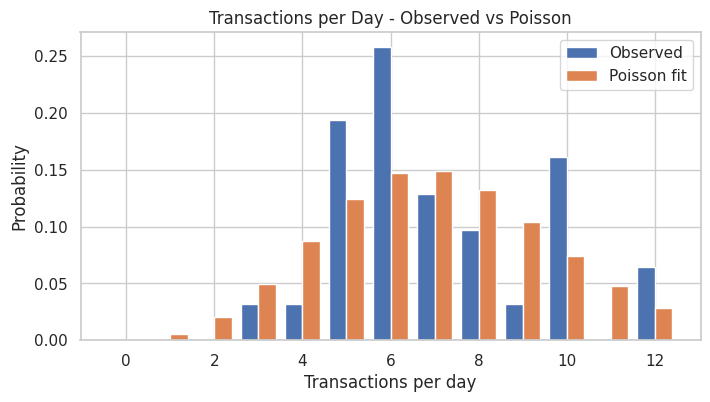

P(exactly 7 transactions in a day) = 0.1489
P(more than 10 transactions in a day) = 0.1055


In [4]:
daily = df.groupby("transaction_date").size()
lam = daily.mean()
print("Lambda (avg transactions per day) =", round(lam, 3))
print("Variance of daily count =", round(daily.var(), 3))

k = np.arange(0, daily.max() + 1)
obs = daily.value_counts(normalize=True).reindex(k, fill_value=0)
exp = stats.poisson.pmf(k, lam)

plt.figure(figsize=(8, 4))
plt.bar(k - 0.2, obs, width=0.4, label="Observed")
plt.bar(k + 0.2, exp, width=0.4, label="Poisson fit")
plt.title("Transactions per Day - Observed vs Poisson")
plt.xlabel("Transactions per day")
plt.ylabel("Probability")
plt.legend()
plt.savefig("charts/2_poisson.png", dpi=150, bbox_inches="tight")
plt.show()

print("P(exactly 7 transactions in a day) =", round(stats.poisson.pmf(7, lam), 4))
print("P(more than 10 transactions in a day) =", round(1 - stats.poisson.cdf(10, lam), 4))

**Interpretation:** The platform gets about 7.1 transactions per day on average (lambda = 7.1). For a Poisson distribution the mean should be close to the variance, and here the variance is 5.29, which is reasonably close, so Poisson is a decent fit. There is about a 14.9% chance of exactly 7 transactions in a day and about a 10.6% chance of more than 10, which helps in planning daily server load and stock.

## Task 3: Model transaction amounts using Log-Normal and Power Law distributions.

Log-normal -> sigma =

 0.4749  scale (e^mu) = 2983.16
Power law (Pareto) -> alpha = 0.763  xmin = 804.42



KS test Normal     : stat = 0.1406  p-value = 0.00029485403065086113
KS test Log-Normal : stat = 0.0378  p-value = 0.8999
KS test Power Law  : stat = 0.3216  p-value = 9.570178201236488e-21


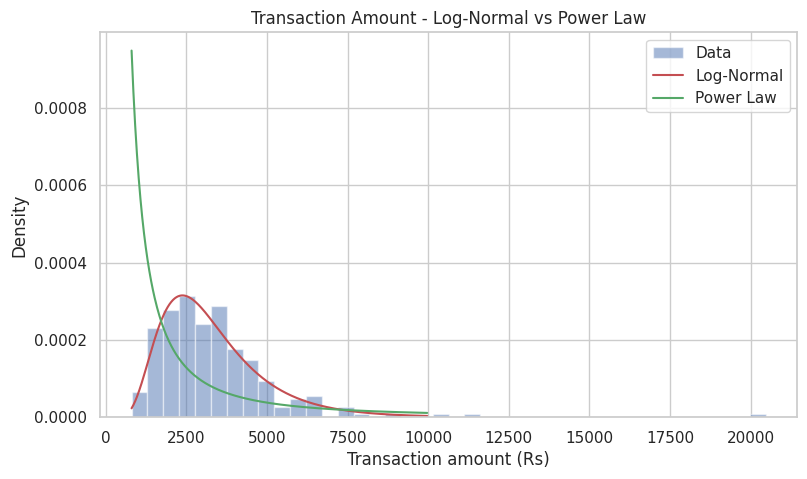

In [5]:
# Log-normal fit
shape, loc, scale = stats.lognorm.fit(amount, floc=0)
print("Log-normal -> sigma =", round(shape, 4), " scale (e^mu) =", round(scale, 2))

# Power law fit (Pareto distribution is the standard power law)
b, loc_p, scale_p = stats.pareto.fit(amount, floc=0)
print("Power law (Pareto) -> alpha =", round(b, 4), " xmin =", round(scale_p, 2))

# KS test (higher p-value = better fit)
ks_ln = stats.kstest(amount, "lognorm", args=(shape, loc, scale))
ks_pl = stats.kstest(amount, "pareto", args=(b, loc_p, scale_p))
ks_norm = stats.kstest(amount, "norm", args=(amount.mean(), amount.std()))
print("\nKS test Normal     : stat =", round(ks_norm.statistic, 4), " p-value =", ks_norm.pvalue)
print("KS test Log-Normal : stat =", round(ks_ln.statistic, 4), " p-value =", round(ks_ln.pvalue, 4))
print("KS test Power Law  : stat =", round(ks_pl.statistic, 4), " p-value =", ks_pl.pvalue)

x = np.linspace(amount.min(), amount.quantile(0.99), 500)
plt.figure(figsize=(9, 5))
plt.hist(amount, bins=40, density=True, alpha=0.5, label="Data")
plt.plot(x, stats.lognorm.pdf(x, shape, loc, scale), "r", label="Log-Normal")
plt.plot(x, stats.pareto.pdf(x, b, loc_p, scale_p), "g", label="Power Law")
plt.title("Transaction Amount - Log-Normal vs Power Law")
plt.xlabel("Transaction amount (Rs)")
plt.ylabel("Density")
plt.legend()
plt.savefig("charts/3_lognormal_powerlaw.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation:** The Log-Normal curve (red) follows the histogram very closely, and its KS test p-value is 0.90 (much greater than 0.05), so we cannot reject that the amounts are Log-Normal. The Power Law curve (green) does not match the data and its KS p-value is almost 0, so it is rejected. The Normal distribution is also rejected (p = 0.0003).

## Task 4: Generate and interpret a Q-Q Plot to test normality.

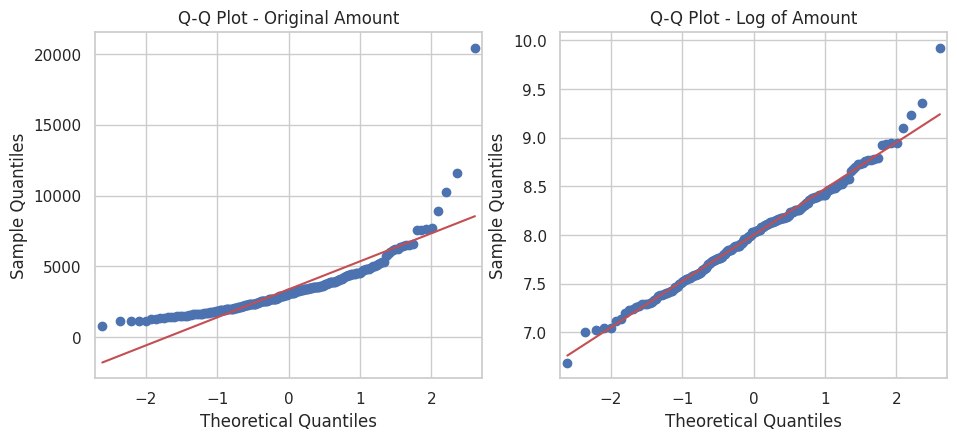

Shapiro test (original): ShapiroResult(statistic=np.float64(0.7360905663247675), pvalue=np.float64(1.9104194773842572e-18))
Shapiro test (log)     : ShapiroResult(statistic=np.float64(0.98942072051413), pvalue=np.float64(0.10614734012895588))


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
sm.qqplot(amount, line="s", ax=ax[0])
ax[0].set_title("Q-Q Plot - Original Amount")
sm.qqplot(np.log(amount), line="s", ax=ax[1])
ax[1].set_title("Q-Q Plot - Log of Amount")
plt.savefig("charts/4_qqplot.png", dpi=150, bbox_inches="tight")
plt.show()

# Shapiro-Wilk test to confirm (p > 0.05 means normal)
print("Shapiro test (original):", stats.shapiro(amount))
print("Shapiro test (log)     :", stats.shapiro(np.log(amount)))

**Interpretation:** In the left plot the points curve away from the red line at the upper end, so the original amounts are **not normal** (right-skewed). Shapiro p-value is almost 0, which confirms this. In the right plot, after taking the log, the points lie close to the line and the Shapiro p-value is 0.106 (> 0.05), so the log of the amount is approximately normal. This supports the Log-Normal model.

## Task 5: Apply Box-Cox Transform to stabilize variance.

Best lambda = -0.1808
Skewness before = 3.73
Skewness after  = -0.011
Variance before = 3943025.97
Variance after  = 0.0123
Shapiro after Box-Cox: ShapiroResult(statistic=np.float64(0.9947291175320323), pvalue=np.float64(0.6418550969254215))


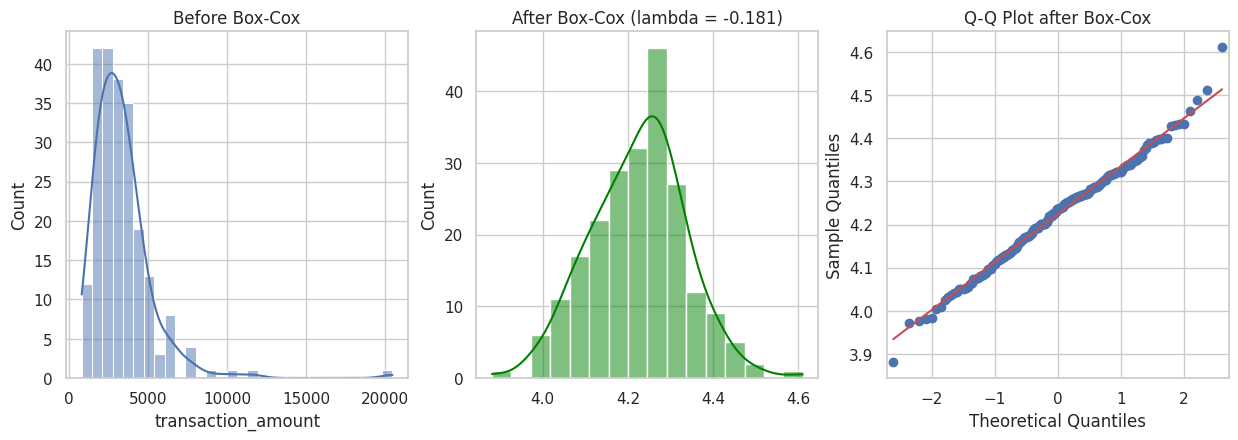

In [7]:
amount_bc, best_lambda = stats.boxcox(amount)
print("Best lambda =", round(best_lambda, 4))
print("Skewness before =", round(stats.skew(amount), 3))
print("Skewness after  =", round(stats.skew(amount_bc), 3))
print("Variance before =", round(amount.var(), 2))
print("Variance after  =", round(np.var(amount_bc), 4))
print("Shapiro after Box-Cox:", stats.shapiro(amount_bc))

fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
sns.histplot(amount, kde=True, ax=ax[0])
ax[0].set_title("Before Box-Cox")
sns.histplot(amount_bc, kde=True, ax=ax[1], color="green")
ax[1].set_title("After Box-Cox (lambda = " + str(round(best_lambda, 3)) + ")")
sm.qqplot(amount_bc, line="s", ax=ax[2])
ax[2].set_title("Q-Q Plot after Box-Cox")
plt.savefig("charts/5_boxcox.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation:** Box-Cox picked lambda = -0.18, which is close to 0, meaning it behaves almost like a log transform (this agrees with the Log-Normal result). Skewness dropped from 3.73 to about -0.01, the histogram became bell-shaped, and the Q-Q plot points now sit on the line. Shapiro p-value is 0.64, so the transformed data is normal and the variance is stabilised. (The variance value changes a lot because the scale of the data changed.)

## Task 6: Calculate Z-scores for transaction amounts and compute probability of transactions exceeding ₹5000.

In [8]:
mean_amt = amount.mean()
std_amt = amount.std()
df["z_score"] = (amount - mean_amt) / std_amt
print("Mean =", round(mean_amt, 2), " Std =", round(std_amt, 2))
print(df[["transaction_amount", "z_score"]].head())
print("Outliers (|z| > 3):", (df["z_score"].abs() > 3).sum())

z_5000 = (5000 - mean_amt) / std_amt
prob_normal = 1 - stats.norm.cdf(z_5000)
prob_lognorm = 1 - stats.lognorm.cdf(5000, shape, loc, scale)
prob_actual = (amount > 5000).mean()

print("\nZ-score of 5000 =", round(z_5000, 4))
print("P(amount > 5000) using z-score (normal) =", round(prob_normal, 4))
print("P(amount > 5000) using log-normal       =", round(prob_lognorm, 4))
print("P(amount > 5000) actual from data       =", round(prob_actual, 4))

Mean = 3365.19  Std = 1985.71
   transaction_amount   z_score
0             3821.34  0.229716
1             2781.84 -0.293776
2             4120.97  0.380609
3             6383.78  1.520159
4             2651.61 -0.359360
Outliers (|z| > 3): 3

Z-score of 5000 = 0.8233
P(amount > 5000) using z-score (normal) = 0.2052
P(amount > 5000) using log-normal       = 0.1384
P(amount > 5000) actual from data       = 0.1136


**Interpretation:** Rs 5000 has a z-score of 0.82, which means it is 0.82 standard deviations above the mean (Rs 3,365). Using the normal z-score method, the probability of a transaction above Rs 5000 is about 20.5%, but the actual share in the data is only 11.4%. The Log-Normal estimate (13.8%) is much closer to reality, so the normal assumption overestimates the chance. 3 transactions have |z| > 3 and are treated as outliers (very large purchases).

## Task 7: Plot and interpret PDF and CDF for transaction amounts.

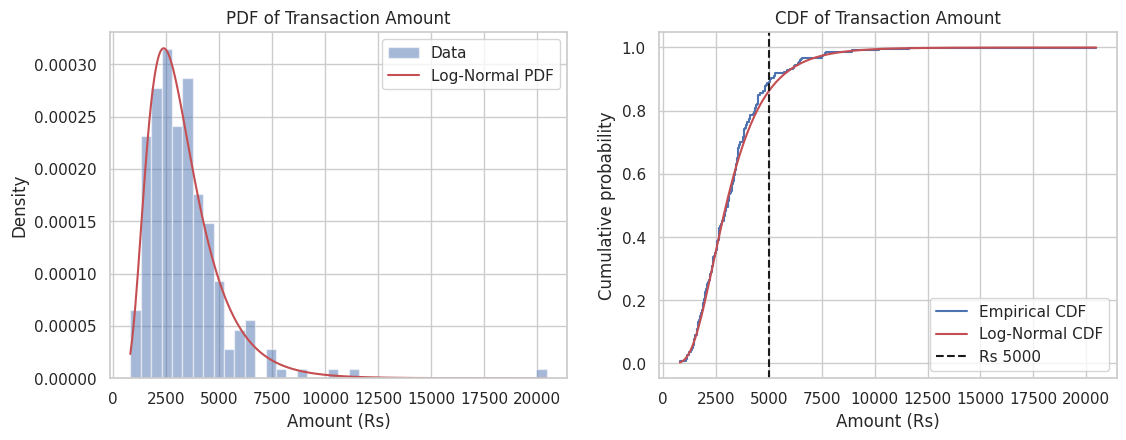

P(amount <= 5000) from CDF = 0.8616


In [9]:
x = np.linspace(amount.min(), amount.max(), 500)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# PDF
ax[0].hist(amount, bins=40, density=True, alpha=0.5, label="Data")
ax[0].plot(x, stats.lognorm.pdf(x, shape, loc, scale), "r", label="Log-Normal PDF")
ax[0].set_title("PDF of Transaction Amount")
ax[0].set_xlabel("Amount (Rs)")
ax[0].set_ylabel("Density")
ax[0].legend()

# CDF
sorted_amt = np.sort(amount)
ecdf = np.arange(1, len(sorted_amt) + 1) / len(sorted_amt)
ax[1].step(sorted_amt, ecdf, label="Empirical CDF")
ax[1].plot(x, stats.lognorm.cdf(x, shape, loc, scale), "r", label="Log-Normal CDF")
ax[1].axvline(5000, color="k", linestyle="--", label="Rs 5000")
ax[1].set_title("CDF of Transaction Amount")
ax[1].set_xlabel("Amount (Rs)")
ax[1].set_ylabel("Cumulative probability")
ax[1].legend()
plt.savefig("charts/7_pdf_cdf.png", dpi=150, bbox_inches="tight")
plt.show()

print("P(amount <= 5000) from CDF =", round(stats.lognorm.cdf(5000, shape, loc, scale), 4))

**Interpretation:** The PDF shows that most transactions are between about Rs 2,000 and Rs 4,500, with a long tail to the right. The CDF shows the cumulative probability: at Rs 5000 the curve is at about 0.86, so roughly 86% of transactions are Rs 5000 or less and only about 14% are above it. The red Log-Normal CDF closely follows the empirical CDF, confirming a good fit.

## Task 8: Conclude which distribution best fits the dataset and justify insights for decision-making.

In [10]:
# AIC = 2*k - 2*log-likelihood (lower AIC = better)
ll_norm = np.sum(stats.norm.logpdf(amount, mean_amt, std_amt))
ll_ln = np.sum(stats.lognorm.logpdf(amount, shape, loc, scale))
ll_pl = np.sum(stats.pareto.logpdf(amount, b, loc_p, scale_p))

comparison = pd.DataFrame({
    "Distribution": ["Normal", "Log-Normal", "Power Law"],
    "AIC": [4 - 2 * ll_norm, 4 - 2 * ll_ln, 4 - 2 * ll_pl],
    "KS_stat": [ks_norm.statistic, ks_ln.statistic, ks_pl.statistic],
    "KS_pvalue": [ks_norm.pvalue, ks_ln.pvalue, ks_pl.pvalue]
})
comparison = comparison.sort_values("AIC")
print(comparison)
print("\nBest fitting distribution:", comparison.iloc[0]["Distribution"])

  Distribution          AIC   KS_stat     KS_pvalue
1   Log-Normal  3821.027805  0.037792  8.998795e-01
0       Normal  3968.573935  0.140601  2.948540e-04
2    Power Law  4083.343774  0.321602  9.570178e-21

Best fitting distribution: Log-Normal


**Interpretation / Conclusion:** Log-Normal has the lowest AIC (about 3821), the smallest KS statistic (0.038) and the only good p-value (0.90). Normal and Power Law fit poorly.

**Insights for decision-making:**
- Transaction amounts are Log-Normal: most customers spend a moderate amount, and a few customers make very large purchases. Business can plan separate offers for these high-value customers.
- Use the log (or Box-Cox) transform before applying models that need normal data.
- About 11 to 14% of transactions exceed Rs 5000, useful for setting premium-customer thresholds and fraud-check limits.
- Daily transaction count follows Poisson (about 7 per day), which helps in capacity planning.
- 55% of transactions fail, so improving payment success is the biggest opportunity.